# 01 — Khảo sát & tiền xử lý dữ liệu giá nhà Hà Nội

**Đề tài:** Dự đoán giá bất động sản dựa trên đặc điểm nhà ở
**Dữ liệu:** [`tinixai/vietnam-real-estates`](https://huggingface.co/datasets/tinixai/vietnam-real-estates) (Hugging Face, CC BY-NC 4.0, ghi công TiniX AI)
**Phạm vi:** tin **bán**, **nhà riêng / nhà phố**, **Hà Nội**

Notebook này làm các bước:

| Bước | Nội dung |
|---|---|
| 1 | Kết nối Google Drive, cấu hình |
| 2 | Tải các shard parquet từ Hugging Face, xem schema, ánh xạ tên cột |
| 3 | **Khảo sát lượt 1**: số tin theo tỉnh, loại hình BĐS tại Hà Nội → quyết định loại hình giữ lại |
| 4 | **Lọc lượt 2**: Hà Nội + nhà riêng/nhà phố, trích đặc trưng văn bản, lưu bản thô |
| 5 | Khảo sát tỷ lệ thiếu trên bản thô |
| 6 | Parse giá (chuỗi → VND), parse số, ngày đăng |
| 7 | Chuẩn hóa địa chỉ (chỗ cắm module NLP chuẩn hóa địa chỉ mới) |
| 8 | Sửa lỗi đơn vị giá (nghìn/triệu/tỷ) |
| 9 | **Khử trùng lặp** (trước khi chia train/test) |
| 10 | Lọc ngoại lai: ngưỡng hợp lý + ngoại lai cục bộ theo phường (robust z-score) |
| 11 | Tạo đặc trưng: log, tỷ lệ, loại đường, khoảng cách tới trung tâm, hướng nhà |
| 12 | Chia train/test, lưu dữ liệu + bảng tổng hợp cho báo cáo lên Google Drive |

> **Không** điền giá trị thiếu / chuẩn hóa (scale) / one-hot ở đây. Các bước đó phải nằm trong `sklearn.Pipeline` ở notebook huấn luyện để **chỉ fit trên tập train của từng fold** → tránh rò rỉ dữ liệu (data leakage).

**Kết quả trên Drive** (`MyDrive/ML_house_price/`):
- `data_processed/02_hanoi_nhapho_clean.parquet` (+ `.csv`), `train.parquet`, `test.parquet`, `feature_config.json`
- `survey/`: các bảng khảo sát, phễu lọc dữ liệu (`funnel.csv`), từ điển dữ liệu — dùng trực tiếp cho báo cáo
- `figures/`: biểu đồ

## 1. Kết nối Google Drive & cấu hình

In [1]:
%pip -q install huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, glob, unicodedata, warnings
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Chạy trên Colab:", IN_COLAB)

Chạy trên Colab: False


In [3]:
# ===================== CẤU HÌNH =====================
def find_project_dir():
    # Thứ tự ưu tiên: (1) biến môi trường ML_PROJECT_DIR; (2) Colab: thư mục dự án trên Google Drive;
    # (3) chạy trên máy: thư mục gốc dự án (nơi có requirements.txt) — thư mục hiện tại hoặc thư mục cha
    if os.environ.get("ML_PROJECT_DIR"):
        return os.environ["ML_PROJECT_DIR"]
    if IN_COLAB:
        return "/content/drive/MyDrive/ML_house_price"
    here = os.path.abspath(os.getcwd())
    for p in (here, os.path.dirname(here)):
        if os.path.isfile(os.path.join(p, "requirements.txt")):
            return p
    return here

PROJECT_DIR = find_project_dir()
OUT_DIR    = f"{PROJECT_DIR}/data_processed"
SURVEY_DIR = f"{PROJECT_DIR}/survey"
FIG_DIR    = f"{PROJECT_DIR}/figures"

# Nguồn dữ liệu: "hf" = tải từ Hugging Face; "drive" = đọc shard parquet đã có sẵn trên Drive
DATA_SOURCE   = "hf"
HF_REPO       = "tinixai/vietnam-real-estates"
# Colab: ổ đĩa tạm /content (nhanh, không tốn dung lượng Drive); trên máy: thư mục raw_parquet/ trong dự án (đã .gitignore)
LOCAL_RAW_DIR = "/content/raw_parquet" if IN_COLAB else f"{PROJECT_DIR}/raw_parquet"
DRIVE_RAW_DIR = f"{PROJECT_DIR}/raw_parquet"     # dùng khi DATA_SOURCE = "drive"

# Nếu tự dò tên cột sai, ghi đè ở đây, ví dụ: {"type": "category_name", "date": "created_at"}
COL_OVERRIDE = {}

# Phạm vi
PROVINCE_KEYWORD = "ha noi"   # so khớp trên tên tỉnh đã bỏ dấu, viết thường
# Loại hình giữ lại / loại bỏ (regex trên chuỗi đã bỏ dấu, viết thường) — xem bảng ở bước 3 rồi chỉnh
# Dữ liệu thật dùng nhãn chung "Nhà" (gồm nhà riêng, nhà phố, nhà trong ngõ) → phải khớp cả "nha" đứng một mình
KEEP_TYPE_RE    = r"^nha$|\bnha\s+(?:rieng|pho|mat\s+pho|mat\s+tien|mat\s+duong|ngo|hem|trong\s+ngo|trong\s+hem)\b"
EXCLUDE_TYPE_RE = (r"chung\s+cu|can\s+ho|biet\s+thu|lien\s+ke|shophouse|condotel|dat\s+nen|^dat\b|\bban\s+dat\b"
                   r"|\bkho\b|xuong|van\s+phong|phong\s+tro|nha\s+tro|khach\s+san|trang\s+trai|mat\s+bang|cho\s+thue")

# Ngưỡng hợp lý cho nhà riêng/nhà phố Hà Nội (giải thích trong báo cáo)
PRICE_MIN, PRICE_MAX = 3e8, 3e11      # 300 triệu – 300 tỷ VND
AREA_MIN,  AREA_MAX  = 10, 1000       # m²
UNIT_MIN,  UNIT_MAX  = 5e6, 2e9       # 5 triệu – 2 tỷ VND/m²
# Giá trị ngoài khoảng → đặt NaN (không xoá dòng); sẽ được điền ở pipeline huấn luyện
PLAUSIBLE = {
    "floor_count":    (1, 15),
    "bedroom_count":  (1, 30),
    "bathroom_count": (1, 30),
    "frontage_width": (1, 50),    # m
    "house_depth":    (2, 200),   # m
    "road_width":     (0.5, 100), # m
}
HANOI_BBOX = (20.5, 21.45, 105.25, 106.05)   # lat_min, lat_max, lon_min, lon_max
CENTER     = (21.0285, 105.8542)             # Hồ Gươm

MIN_FEATURE_COVERAGE = 0.10   # đặc trưng số có dữ liệu ở < 10% số tin thì bỏ (không đủ thông tin để điền)
ROBUST_Z   = 3.5   # ngưỡng robust z-score của log(đơn giá) trong cùng phường
MIN_WARD_N = 20    # phường có ít tin hơn → so với phân phối toàn thành phố
TEST_SIZE, SEED = 0.2, 42

# File ánh xạ địa chỉ cũ → mới (đầu ra của module NLP), tuỳ chọn.
# Cột yêu cầu: district_key, ward_key, ward_new  (khoá = tên đã bỏ dấu, bỏ tiền tố "phường/quận")
ADDRESS_MAPPING_CSV = f"{PROJECT_DIR}/address_mapping.csv"

for d in [OUT_DIR, SURVEY_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)
print("Lưu kết quả vào:", PROJECT_DIR)

Lưu kết quả vào: D:\HocMay_GiaNha_KT1


### Hàm tiện ích
- `norm_key`: bỏ dấu, viết thường, bỏ ký tự đặc biệt → khoá so khớp ổn định ("Phường Dịch Vọng" → "phuong dich vong").
- `to_float_vn`: đọc số kiểu Việt Nam ("8,5" = 8.5; "1.234.567" = 1234567).
- `parse_price`: đọc giá dạng chuỗi ("8,5 tỷ", "850 triệu", "8 tỷ 500", "120 triệu/m²", "Thỏa thuận").
- `log_step`: ghi **phễu lọc dữ liệu** (số dòng sau mỗi bước) — bảng này đưa thẳng vào báo cáo.

In [4]:
def strip_accents(s: str) -> str:
    s = unicodedata.normalize("NFD", s)
    s = "".join(ch for ch in s if unicodedata.category(ch) != "Mn")
    return s.replace("đ", "d").replace("Đ", "D")

def norm_key(x) -> str:
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return ""
    s = strip_accents(str(x)).lower()
    return re.sub(r"[^a-z0-9]+", " ", s).strip()

def map_unique(s: pd.Series, func) -> pd.Series:
    # Áp func lên giá trị duy nhất rồi map lại — nhanh hơn apply trên hàng trăm nghìn dòng
    uniq = s.dropna().unique()
    return s.map(dict(zip(uniq, [func(u) for u in uniq])))

def keys_of(s: pd.Series) -> pd.Series:
    return map_unique(s, norm_key).fillna("").astype(str)

NUM_RE = re.compile(r"\d+(?:[.,]\d+)*")

def to_float_vn(tok: str) -> float:
    tok = tok.strip()
    if "," in tok and "." in tok:
        # dấu xuất hiện sau cùng là dấu thập phân
        tok = tok.replace(".", "").replace(",", ".") if tok.rfind(",") > tok.rfind(".") else tok.replace(",", "")
    else:
        sep = "," if "," in tok else ("." if "." in tok else None)
        if sep:
            parts = tok.split(sep)
            if len(parts) > 2 or (len(parts[-1]) == 3 and parts[0] != "0"):
                tok = tok.replace(sep, "")      # phân cách hàng nghìn
            else:
                tok = tok.replace(sep, ".")     # dấu thập phân
    try:
        return float(tok)
    except ValueError:
        return np.nan

def parse_number(x) -> float:
    if x is None:
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)
    m = NUM_RE.search(str(x))
    return to_float_vn(m.group()) if m else np.nan

def to_numeric_col(s: pd.Series) -> pd.Series:
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    return map_unique(s, parse_number).astype(float)

PRICE_UNITS = {"ty": 1e9, "trieu": 1e6, "tr": 1e6, "nghin": 1e3, "ngan": 1e3, "k": 1e3}
PRICE_TOKEN_RE = re.compile(r"(\d+(?:[.,]\d+)*)\s*(ty|trieu|tr|nghin|ngan|k)?(?![a-z])")

def parse_price(x):
    # Trả về (giá VND, cờ "giá theo m²")
    if x is None:
        return (np.nan, False)
    if isinstance(x, (int, float, np.integer, np.floating)):
        return (np.nan, False) if pd.isna(x) else (float(x), False)
    s = strip_accents(str(x)).lower().strip()
    if not s or re.search(r"thoa\s*thuan|lien\s*he|deal", s):
        return (np.nan, False)
    per_m2 = bool(re.search(r"/\s*m", s))
    tokens = PRICE_TOKEN_RE.findall(s)
    if not tokens:
        return (np.nan, per_m2)
    if not any(u for _, u in tokens):
        return (to_float_vn(tokens[0][0]), per_m2)
    total, prev_unit = 0.0, None
    for num, unit in tokens:
        v = to_float_vn(num)
        if np.isnan(v):
            continue
        if unit:
            total += v * PRICE_UNITS[unit]
            prev_unit = unit
        elif prev_unit == "ty" and v < 1000:   # "8 tỷ 500" = 8 tỷ 500 triệu
            total += v * 1e6
            prev_unit = None
    return (total if total > 0 else np.nan, per_m2)

def parse_price_col(s: pd.Series):
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(float), pd.Series(False, index=s.index)
    parsed = {u: parse_price(u) for u in s.dropna().unique()}
    val = s.map({k: v[0] for k, v in parsed.items()}).astype(float)
    pm2 = s.map({k: v[1] for k, v in parsed.items()}).eq(True)
    return val, pm2

def find_col(cols, candidates):
    low = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in low:
            return low[cand.lower()]
    return None

FUNNEL = []
def log_step(step, n, note=""):
    prev = FUNNEL[-1]["rows"] if FUNNEL else None
    FUNNEL.append({"step": step, "rows": int(n),
                   "removed": 0 if prev is None else int(prev - n), "note": note})
    print(f"[{step}] {n:,} dòng" + ("" if prev is None else f"  (−{prev - n:,})") + (f" — {note}" if note else ""))

def save_df(df, name, csv=False):
    path = os.path.join(OUT_DIR, f"{name}.parquet")
    df.to_parquet(path, index=False)
    if csv:
        df.to_csv(path[:-8] + ".csv", index=False, encoding="utf-8-sig")
    print("Đã lưu:", path, df.shape)

def save_table(df, name):
    path = os.path.join(SURVEY_DIR, f"{name}.csv")
    df.to_csv(path, encoding="utf-8-sig")
    print("Đã lưu:", path)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# quick self-test
assert parse_price("8,5 tỷ")[0] == 8.5e9
assert parse_price("850 triệu")[0] == 8.5e8
assert parse_price("8 tỷ 500")[0] == 8.5e9
assert parse_price("120 triệu/m²") == (1.2e8, True)
assert np.isnan(parse_price("Thỏa thuận")[0])
assert parse_price("8500000000")[0] == 8.5e9
assert to_float_vn("1.234.567") == 1234567 and to_float_vn("98,5") == 98.5
print("Hàm tiện ích OK")

Hàm tiện ích OK


## 2. Tải dữ liệu & xem schema
Dữ liệu gồm nhiều shard parquet (~170 MB/shard). Tải về ổ đĩa tạm của Colab (`/content`) thay vì Drive cho nhanh.
Notebook đọc **từng shard một và chỉ các cột cần thiết** để không tràn RAM.

In [5]:
if DATA_SOURCE == "hf":
    from huggingface_hub import snapshot_download
    RAW_DIR = snapshot_download(repo_id=HF_REPO, repo_type="dataset",
                                allow_patterns=["*.parquet"], local_dir=LOCAL_RAW_DIR)
else:
    RAW_DIR = DRIVE_RAW_DIR

files = sorted(glob.glob(os.path.join(RAW_DIR, "**", "*.parquet"), recursive=True))
assert files, f"Không tìm thấy file .parquet trong {RAW_DIR}"
rows_per_file = {os.path.basename(f): pq.ParquetFile(f).metadata.num_rows for f in files}
print(f"{len(files)} shard, tổng {sum(rows_per_file.values()):,} dòng")
print(rows_per_file)

pf = pq.ParquetFile(files[0])
ALL_COLS = list(pf.schema_arrow.names)
print("\nSchema:\n", pf.schema_arrow)
sample = next(pf.iter_batches(batch_size=5)).to_pandas()
display(sample.T)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

10 shard, tổng 3,500,744 dòng
{'shard_0000.parquet': 350075, 'shard_0001.parquet': 350075, 'shard_0002.parquet': 350075, 'shard_0003.parquet': 350075, 'shard_0004.parquet': 350074, 'shard_0005.parquet': 350074, 'shard_0006.parquet': 350074, 'shard_0007.parquet': 350074, 'shard_0008.parquet': 350074, 'shard_0009.parquet': 350074}

Schema:
 name: string
description: string
property_type_name: string
province_name: string
district_name: string
ward_name: string
street_name: string
project_name: string
price: string
area: double
floor_count: double
frontage_width: double
house_depth: double
road_width: double
bedroom_count: double
bathroom_count: double
house_direction: string
balcony_direction: string
published_at: string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 2416


,0,1,2,3,4
name,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ...",Bán gấp nhà mặt tiền 4 tầng khu phân lô Tạ Qua...,"Bán biệt thự 300m2 gần sân bóng Bình Minh, đườ...","Cần bán căn hộ CC Thái An, Nguyễn Văn Quá, Q12...","MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ..."
description,"- Vị trí siêu đẹp ô tô đỗ cổng, khu vực đang p...",Nhà 4 tầng mặt tiền KDC Tạ Quang Bửu P5 Q8. - ...,Bán biệt thự Bình Minh diện tích hơn 300 mét v...,"Chung cư Thái An đường Nguyễn Văn Quá, Đông Hư...","MTKD p.Tân Thành, Tân Phú, dt 4x15m sẵn hợp đồ..."
property_type_name,Nhà,Nhà,Biệt thự/Nhà liền kề,Căn hộ chung cư,Nhà
province_name,Hà Nội,Hồ Chí Minh,Vĩnh Long,Hồ Chí Minh,Hồ Chí Minh
district_name,Bắc Từ Liêm,8,Bình Minh,12,Tân Phú
ward_name,Phúc Diễn,5,None,Đông Hưng Thuận,Tân Thành
street_name,Ngọa Long,Tạ Quang Bửu,None,Nguyễn Văn Quá,Nguyễn Hậu
project_name,None,None,None,Thái An Apartment,None
price,7450000000,9100000000,20000000000,1300000000,9000000000
area,37.0,48.0,300.0,44.0,60.0


### Ánh xạ tên cột
Tự dò tên cột theo danh sách ứng viên và đổi về tên chuẩn dùng trong notebook. **Kiểm tra bảng in ra**; nếu dò sai/thiếu, sửa `COL_OVERRIDE` ở ô cấu hình rồi chạy lại từ đầu.

In [6]:
CANDIDATES = {
    "id":             ["id", "listing_id", "post_id", "product_id"],
    "date":           ["published_at", "publish_date", "published_date", "posted_at", "post_date",
                       "created_at", "listing_date", "date", "created_date", "updated_at"],
    "province":       ["province_name", "province", "city_name", "city"],
    "district":       ["district_name", "district"],
    "ward":           ["ward_name", "ward"],
    "street":         ["street_name", "street"],
    "type":           ["property_type", "property_type_name", "category_name", "category",
                       "real_estate_type", "estate_type", "type_name", "type"],
    "price":          ["price", "price_vnd"],
    "area":           ["area", "acreage", "size"],
    "floor_count":    ["floor_count", "floors", "num_floors"],
    "frontage_width": ["frontage_width", "frontage"],
    "house_depth":    ["house_depth", "depth"],
    "road_width":     ["road_width", "alley_width"],
    "bedroom_count":  ["bedroom_count", "bedrooms", "num_bedrooms"],
    "bathroom_count": ["bathroom_count", "bathrooms", "toilet_count", "num_bathrooms"],
    "house_direction":["house_direction", "direction"],
    "lat":            ["latitude", "lat"],
    "lon":            ["longitude", "lon", "lng"],
    "title":          ["name", "title"],
    "desc":           ["description", "content", "desc"],
}
C = {k: find_col(ALL_COLS, v) for k, v in CANDIDATES.items()}
C.update(COL_OVERRIDE)

mapping = pd.DataFrame({"tên chuẩn": list(C), "cột trong dữ liệu": [C[k] for k in C]})
display(mapping)

for k in ["province", "price", "area"]:
    assert C[k], f"Thiếu cột bắt buộc '{k}' — đặt trong COL_OVERRIDE"
dup = pd.Series([v for v in C.values() if v]).value_counts()
assert (dup == 1).all(), f"Một cột bị gán cho nhiều tên chuẩn: {dup[dup > 1].to_dict()}"
missing = [k for k, v in C.items() if v is None]
if missing:
    print("⚠ Không tìm thấy:", missing, "— các bước liên quan sẽ được bỏ qua")
if not C["type"]:
    print("⚠ Không có cột loại hình → sẽ lọc nhà riêng/nhà phố bằng tiêu đề tin")

,tên chuẩn,cột trong dữ liệu
0,id,None
1,date,published_at
2,province,province_name
3,district,district_name
4,ward,ward_name
5,street,street_name
6,type,property_type_name
7,price,price
8,area,area
9,floor_count,floor_count


⚠ Không tìm thấy: ['id', 'lat', 'lon'] — các bước liên quan sẽ được bỏ qua


## 3. Khảo sát lượt 1: phân bố theo tỉnh & loại hình
Chỉ đọc 2 cột (tỉnh, loại hình) nên rất nhanh. Bảng loại hình tại Hà Nội có cột `keep` cho biết loại nào sẽ được giữ theo `KEEP_TYPE_RE` / `EXCLUDE_TYPE_RE`.
**Hãy đọc bảng này**: nếu có loại hình nhà riêng/nhà phố bị bỏ sót hoặc giữ nhầm, sửa regex ở ô cấu hình và chạy lại.

In [7]:
def read_cols(f, cols):
    return pd.read_parquet(f, columns=[c for c in dict.fromkeys(cols) if c])

def is_hanoi(s):
    return keys_of(s).str.contains(PROVINCE_KEYWORD, regex=False)

def type_keep(s):
    k = keys_of(s)
    return k.str.contains(KEEP_TYPE_RE, regex=True) & ~k.str.contains(EXCLUDE_TYPE_RE, regex=True)

def title_keep(s):   # dự phòng khi không có cột loại hình
    k = keys_of(s)
    return k.str.contains(r"\bnha\b", regex=True) & ~k.str.contains(EXCLUDE_TYPE_RE, regex=True)

FUNNEL.clear()
prov_parts, type_parts, n_total = [], [], 0
for f in files:
    d = read_cols(f, [C["province"], C["type"]])
    n_total += len(d)
    prov_parts.append(d[C["province"]].value_counts(dropna=False))
    if C["type"]:
        type_parts.append(d.loc[is_hanoi(d[C["province"]]), C["type"]].value_counts(dropna=False))
log_step("Toàn bộ dữ liệu", n_total)

prov_counts = pd.concat(prov_parts).groupby(level=0, dropna=False).sum().sort_values(ascending=False)
prov_counts = prov_counts.rename("so_tin").to_frame()
prov_counts["ty_le_%"] = (prov_counts["so_tin"] / n_total * 100).round(2)
print("\nTop 10 tỉnh/thành theo số tin:")
display(prov_counts.head(10))
save_table(prov_counts, "01_so_tin_theo_tinh")

if C["type"]:
    type_counts = pd.concat(type_parts).groupby(level=0, dropna=False).sum().sort_values(ascending=False)
    type_counts = type_counts.rename("so_tin").to_frame()
    type_counts["ty_le_%"] = (type_counts["so_tin"] / type_counts["so_tin"].sum() * 100).round(2)
    type_counts["keep"] = type_keep(pd.Series(type_counts.index, index=type_counts.index))
    print("\nLoại hình BĐS tại Hà Nội:")
    display(type_counts)
    save_table(type_counts, "02_loai_hinh_ha_noi")
    print(f"→ Giữ {type_counts.loc[type_counts['keep'], 'so_tin'].sum():,} / {type_counts['so_tin'].sum():,} tin Hà Nội")
    assert type_counts["keep"].any(), "Không loại hình nào được giữ — sửa KEEP_TYPE_RE ở ô cấu hình rồi chạy lại"

[Toàn bộ dữ liệu] 3,500,744 dòng

Top 10 tỉnh/thành theo số tin:


,so_tin,ty_le_%
province_name,,
Hồ Chí Minh,1357526,38.78
Hà Nội,1140542,32.58
Đà Nẵng,185973,5.31
Bình Dương,150377,4.30
Khánh Hòa,98377,2.81
Hải Phòng,72788,2.08
Hưng Yên,65223,1.86
Đồng Nai,59543,1.70
Long An,47125,1.35


Đã lưu: D:\HocMay_GiaNha_KT1/survey\01_so_tin_theo_tinh.csv

Loại hình BĐS tại Hà Nội:


,so_tin,ty_le_%,keep
property_type_name,,,
Nhà,549408,48.17,True
Căn hộ chung cư,303589,26.62,False
Đất,181534,15.92,False
Biệt thự/Nhà liền kề,92936,8.15,False
Shophouse,13075,1.15,False


Đã lưu: D:\HocMay_GiaNha_KT1/survey\02_loai_hinh_ha_noi.csv
→ Giữ 549,408 / 1,140,542 tin Hà Nội


## 4. Lọc lượt 2: Hà Nội + nhà riêng/nhà phố, trích đặc trưng văn bản
Với mỗi shard: lọc Hà Nội và loại hình, đổi tên cột về tên chuẩn, trích **cờ nhị phân từ tiêu đề + mô tả** bằng regex, tính **mã băm mô tả** (dùng để khử trùng lặp) rồi **bỏ cột mô tả** để tiết kiệm RAM.

Các cờ văn bản (regex chạy trên chữ thường, có dấu, kèm biến thể không dấu phổ biến):

| Cờ | Ý nghĩa |
|---|---|
| `has_so_do` | Có sổ đỏ / sổ hồng |
| `car_access` | Ô tô vào / đỗ cửa / gara |
| `is_mat_pho` | Mặt phố / mặt đường |
| `kinh_doanh` | Kinh doanh được / vỉa hè |
| `lo_goc` | Lô góc / hai mặt thoáng |
| `no_hau` | Nở hậu |
| `thang_may` | Có thang máy |

> Lưu ý rò rỉ: mô tả thường chứa chính giá ("giá 8,5 tỷ") — **không** trích con số giá từ mô tả làm đặc trưng.

In [8]:
TEXT_FLAGS = {
    "has_so_do":  r"sổ\s*(?:đỏ|hồng|riêng|chính\s*chủ|vuông|nét|sẵn|đẹp)|sđcc|\bsdcc\b|so\s*hong|so\s*do\s*chinh\s*chu",
    "car_access": r"(?:ô\s*tô|ôtô|oto|xe\s*hơi)\s*(?:\d+\s*chỗ\s*)?(?:vào|đỗ|đậu|tránh|chạy|lùi|ngủ|qua|vao|do\b|tranh)"
                  r"|ngõ\s*(?:ô\s*tô|ôtô|oto)|ngo\s*oto|\bgara\b|garage",
    "is_mat_pho": r"mặt\s*(?:phố|đường)|\bmat\s*pho\b|\bmat\s*duong\b",
    "kinh_doanh": r"kinh\s*doanh|buôn\s*bán|vỉa\s*hè|kinh\s*doanh|\bvia\s*he\b|\bkd\b",
    "lo_goc":     r"lô\s*góc|căn\s*góc|\blo\s*goc\b|hai\s*mặt\s*(?:thoáng|tiền|ngõ)|2\s*mặt\s*(?:thoáng|tiền|ngõ)",
    "no_hau":     r"nở\s*hậu|\bno\s*hau\b",
    "thang_may":  r"thang\s*máy|\bthang\s*may\b",
}
STD_KEYS = ["id", "date", "province", "district", "ward", "street", "type", "price", "area",
            "floor_count", "frontage_width", "house_depth", "road_width", "bedroom_count",
            "bathroom_count", "house_direction", "lat", "lon", "title", "desc"]
use_cols = [C[k] for k in STD_KEYS if C.get(k)]
rename = {C[k]: k for k in STD_KEYS if C.get(k)}

parts, n_hn, n_type = [], 0, 0
for i, f in enumerate(files, 1):
    d = read_cols(f, use_cols).rename(columns=rename)
    d = d[is_hanoi(d["province"])]
    n_hn += len(d)
    d = d[type_keep(d["type"]) if "type" in d else title_keep(d["title"])].copy()
    n_type += len(d)

    title = d["title"].fillna("").astype(str) if "title" in d else pd.Series("", index=d.index)
    desc = d["desc"].fillna("").astype(str) if "desc" in d else pd.Series("", index=d.index)
    text = (title + " . " + desc).str.normalize("NFC").str.lower()
    for name, pat in TEXT_FLAGS.items():
        d[name] = text.str.contains(pat, regex=True).astype("int8")
    dn = desc.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    d["desc_len"] = dn.str.len()
    d["desc_hash"] = pd.util.hash_pandas_object(dn, index=False).values
    d = d.drop(columns=["desc"], errors="ignore")
    parts.append(d)
    print(f"shard {i}/{len(files)}: giữ {len(d):,} dòng")

df = pd.concat(parts, ignore_index=True)
del parts
log_step("Tỉnh = Hà Nội", n_hn)
log_step("Loại hình = nhà riêng/nhà phố", n_type, "theo KEEP_TYPE_RE/EXCLUDE_TYPE_RE")
assert n_type > 0, "Không còn tin nào sau khi lọc loại hình — xem bảng loại hình ở bước 3 và sửa KEEP_TYPE_RE"

# đảm bảo đủ cột chuẩn (cột không có trong dữ liệu → NaN) để các bước sau chạy ổn định
for c in ["area", "floor_count", "frontage_width", "house_depth", "road_width",
          "bedroom_count", "bathroom_count", "lat", "lon"]:
    if c not in df:
        df[c] = np.nan
for c in ["district", "ward", "street", "house_direction", "title"]:
    if c not in df:
        df[c] = ""
if "date" not in df:
    df["date"] = pd.NaT

save_df(df, "01_hanoi_nhapho_raw")
display(df.head())

shard 1/10: giữ 65,291 dòng


shard 2/10: giữ 62,626 dòng


shard 3/10: giữ 61,610 dòng


shard 4/10: giữ 60,885 dòng


shard 5/10: giữ 60,252 dòng


shard 6/10: giữ 57,602 dòng


... (2 outputs left out)

shard 9/10: giữ 40,915 dòng


shard 10/10: giữ 41,933 dòng
[Tỉnh = Hà Nội] 1,140,542 dòng  (−2,360,202)
[Loại hình = nhà riêng/nhà phố] 549,408 dòng  (−591,134) — theo KEEP_TYPE_RE/EXCLUDE_TYPE_RE


Đã lưu: D:\HocMay_GiaNha_KT1/data_processed\01_hanoi_nhapho_raw.parquet (549408, 27)


,date,province,district,ward,street,type,price,area,floor_count,frontage_width,house_depth,road_width,bedroom_count,bathroom_count,house_direction,title,has_so_do,car_access,is_mat_pho,kinh_doanh,lo_goc,no_hau,thang_may,desc_len,desc_hash,lat,lon
0,2025-06-01T05:12:56.941000,Hà Nội,Bắc Từ Liêm,Phúc Diễn,Ngọa Long,Nhà,7450000000,37.0,NaN,NaN,NaN,NaN,4.0,5.0,None,"Bán nhanh nhà 6 tầng thang máy, ngoạ long cầu ...",1,1,0,0,0,0,1,500,11595329277515253508,NaN,NaN
1,2025-06-23T02:19:27.548000,Hà Nội,Cầu Giấy,Nghĩa Tân,Hoàng Quốc Việt,Nhà,16700000000,41.0,NaN,4.1,NaN,NaN,4.0,3.0,None,"Phân lô, ô tô, vỉa hè - Phố Hoàng Quốc Việt, C...",1,1,1,1,0,0,0,255,6709444786826062216,NaN,NaN
2,2025-06-27T07:48:43.661000,Hà Nội,Nam Từ Liêm,Mỹ Đình 2,Lê Đức Thọ,Nhà,8900000000,42.0,NaN,NaN,NaN,NaN,NaN,NaN,None,Bán Nhà Ngõ 35 Lê Đức Thọ Mỹ Đình - 5 tầng - f...,1,1,1,0,0,1,0,446,9700073916822257095,NaN,NaN
3,2025-06-03T17:43:58.207000,Hà Nội,Long Biên,Bồ Đề,Nguyễn Văn Cừ,Nhà,580000000000,1200.0,NaN,19.0,NaN,NaN,NaN,NaN,None,Chính chủ bán đất tặng 2 tòa nhà - mặt phố ngu...,1,0,1,0,0,0,0,497,1016025427037098861,NaN,NaN
4,2025-06-25T12:06:07.580000,Hà Nội,Ba Đình,Ngọc Hà,Hoàng Hoa Thám,Nhà,5350000000,32.0,NaN,NaN,NaN,NaN,3.0,3.0,None,Bán nhà Hoàng Hoa Thám - Ngọc Hà - Ba Đình - 3...,1,0,0,0,0,1,0,308,13296678318318217650,NaN,NaN


## 5. Khảo sát bản thô: tỷ lệ thiếu
Chuỗi rỗng cũng được tính là thiếu. Bảng này dùng để giải thích các quyết định ở bước sau (ví dụ: mặt tiền/đường vào thiếu nhiều → điền median + cờ thiếu ở pipeline, **không** điền 0).

,thieu_%
lat,100.00
lon,100.00
house_depth,98.93
house_direction,87.88
road_width,80.13
floor_count,55.15
bathroom_count,46.48
frontage_width,40.60
bedroom_count,39.67
street,17.74


Đã lưu: D:\HocMay_GiaNha_KT1/survey\03_ty_le_thieu_ban_tho.csv


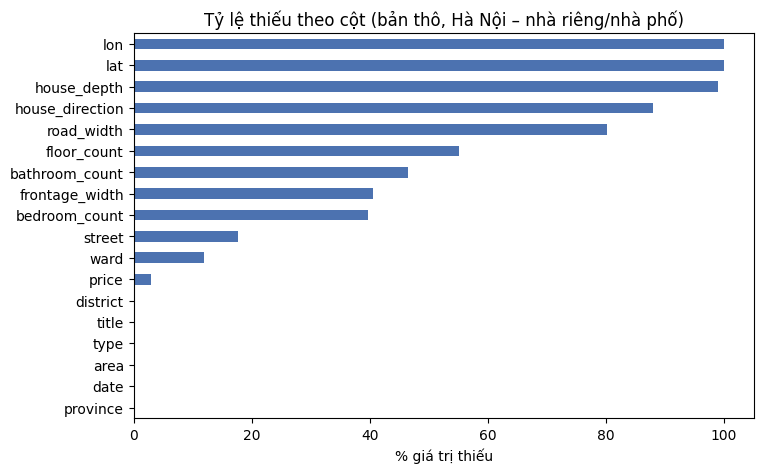

Tỷ lệ tin có từng cờ văn bản:


,ty_le_%
has_so_do,73.05
car_access,50.98
is_mat_pho,23.19
kinh_doanh,40.96
lo_goc,22.91
no_hau,7.67
thang_may,31.61


Đã lưu: D:\HocMay_GiaNha_KT1/survey\04_ty_le_co_van_ban.csv


In [9]:
def missing_table(frame):
    m = frame.isna() | frame.astype(str).apply(lambda s: s.str.strip().eq(""))
    return (m.mean() * 100).round(2).sort_values(ascending=False).rename("thieu_%").to_frame()

skip = list(TEXT_FLAGS) + ["desc_hash", "desc_len"]
miss_raw = missing_table(df.drop(columns=skip))
display(miss_raw)
save_table(miss_raw, "03_ty_le_thieu_ban_tho")

fig, ax = plt.subplots(figsize=(8, 5))
miss_raw["thieu_%"].sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("% giá trị thiếu"); ax.set_title("Tỷ lệ thiếu theo cột (bản thô, Hà Nội – nhà riêng/nhà phố)")
save_fig(fig, "01_ty_le_thieu_ban_tho")

flag_rate = (df[list(TEXT_FLAGS)].mean() * 100).round(2).rename("ty_le_%").to_frame()
print("Tỷ lệ tin có từng cờ văn bản:"); display(flag_rate)
save_table(flag_rate, "04_ty_le_co_van_ban")

## 6. Parse giá, số và ngày đăng
- Giá có thể lưu ở dạng chuỗi ("8,5 tỷ") dù dataset card khai báo `float64` → parse thủ công.
- Giá ghi theo m² ("120 triệu/m²") → nhân với diện tích.
- "Thỏa thuận" / "Liên hệ" → thiếu giá → bị loại (không thể dùng làm nhãn).

In [10]:
df["price_raw"] = df["price"].astype(str)
for c in ["area", "floor_count", "frontage_width", "house_depth", "road_width",
          "bedroom_count", "bathroom_count", "lat", "lon"]:
    df[c] = to_numeric_col(df[c])

val, pm2 = parse_price_col(df["price"])
df["price"] = np.where(pm2 & df["area"].gt(0), val * df["area"], val)
print(f"Giá theo m² đã quy đổi: {int(pm2.sum()):,} tin | giá không đọc được/thỏa thuận: {int(np.isnan(val).sum()):,} tin")

def to_datetime_col(s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return s
    if pd.api.types.is_numeric_dtype(s):       # epoch giây hoặc mili-giây
        unit = "ms" if s.dropna().median() > 1e11 else "s"
        return pd.to_datetime(s, unit=unit, errors="coerce")
    return pd.to_datetime(s, errors="coerce")

df["date"] = to_datetime_col(df["date"])
if hasattr(df["date"].dt, "tz") and df["date"].dt.tz is not None:
    df["date"] = df["date"].dt.tz_localize(None)
print("Khoảng ngày đăng:", df["date"].min(), "→", df["date"].max())
display(df[["price_raw", "price", "area"]].sample(min(10, len(df)), random_state=SEED))

Giá theo m² đã quy đổi: 0 tin | giá không đọc được/thỏa thuận: 16,021 tin


Khoảng ngày đăng: 2025-06-01 00:18:52.602000 → 2026-03-30 23:58:16.386000


,price_raw,price,area
201027,34900000000,3.490000e+10,80.0
49052,15800000000,1.580000e+10,45.0
109492,9300000000,9.300000e+09,35.0
483730,8400000000,8.400000e+09,56.0
187179,12000000000,1.200000e+10,60.0
178348,17500000000,1.750000e+10,64.0
272015,19000000000,1.900000e+10,60.0
467772,15700000000,1.570000e+10,48.0
368711,13000000000,1.300000e+10,54.0
353442,None,NaN,40.0


## 7. Chuẩn hóa địa chỉ (chỗ cắm module NLP)
Tạo khoá `district_key`, `ward_key`, `street_key` (bỏ dấu, bỏ tiền tố "phường/quận/huyện/xã/thị trấn", ví dụ "Quận 8" và "8" cùng thành `8`).

`ward_new` = **phường/xã theo đơn vị hành chính mới (sau sáp nhập 7/2025)**:
- Nếu có file `address_mapping.csv` (đầu ra module chuẩn hóa địa chỉ của đề tài NLP) với cột `district_key, ward_key, ward_new` → ghép vào.
- Nếu chưa có → tạm dùng `ward_key` cũ, và in số phường chưa được ánh xạ.

Có thể thay hàm `normalize_to_new_units` bằng lời gọi trực tiếp tới module của bạn.

In [11]:
# Tiền tố tách riêng cho phường và quận: nếu dùng chung, tên phường "Quan Hoa", "Quán Thánh"
# sẽ bị cắt nhầm chữ "quan" thành "hoa", "thanh"
WARD_PREFIX_RE     = r"^(?:phuong|xa|thi\s+tran|p|x|tt)\s+"
DISTRICT_PREFIX_RE = r"^(?:quan|huyen|thi\s+xa|thanh\s+pho|tp|q|h|tx)\s+"

def admin_key(s, prefix_re):
    return keys_of(s).str.replace(prefix_re, "", regex=True).str.strip()

df["district_key"] = admin_key(df["district"], DISTRICT_PREFIX_RE)
df["ward_key"]     = admin_key(df["ward"], WARD_PREFIX_RE)
df["street_key"]   = keys_of(df["street"]).str.replace(r"^(?:duong|pho|ngo|ngach|hem)\s+", "", regex=True)

def normalize_to_new_units(frame):
    # TODO: thay bằng module chuẩn hoá địa chỉ cũ → mới (đề tài NLP) nếu muốn gọi trực tiếp
    if os.path.exists(ADDRESS_MAPPING_CSV):
        mp = pd.read_csv(ADDRESS_MAPPING_CSV, dtype=str)[["district_key", "ward_key", "ward_new"]].drop_duplicates(
            ["district_key", "ward_key"])
        frame = frame.merge(mp, on=["district_key", "ward_key"], how="left")
        n_miss = frame["ward_new"].isna().sum()
        print(f"Đã ghép address_mapping.csv — {n_miss:,} tin chưa ánh xạ được (giữ ward_key cũ)")
        frame["ward_new"] = frame["ward_new"].fillna(frame["ward_key"])
    else:
        print("Chưa có address_mapping.csv → tạm dùng ward_key (đơn vị cũ) làm ward_new")
        frame["ward_new"] = frame["ward_key"]
    frame["ward_new"] = frame["ward_new"].replace("", "unknown")
    return frame

df = normalize_to_new_units(df)
print(f"Số quận/huyện (cũ): {df['district_key'].nunique():,} | số phường/xã: {df['ward_new'].nunique():,}")

# Xuất danh sách (quận, phường) duy nhất để chạy qua module NLP rồi tạo address_mapping.csv
uniq_addr = (df.groupby(["district_key", "ward_key"]).size().rename("so_tin").reset_index()
               .sort_values("so_tin", ascending=False))
save_table(uniq_addr.set_index(["district_key", "ward_key"]), "05_danh_sach_dia_chi_can_chuan_hoa")

Chưa có address_mapping.csv → tạm dùng ward_key (đơn vị cũ) làm ward_new
Số quận/huyện (cũ): 30 | số phường/xã: 427
Đã lưu: D:\HocMay_GiaNha_KT1/survey\05_danh_sach_dia_chi_can_chuan_hoa.csv


## 8. Sửa lỗi đơn vị giá
Một số tin lưu giá theo nghìn/triệu đồng (ví dụ ghi "10 tỷ" nhưng lưu `10.000.000`). Với tin có giá < `PRICE_MIN`, thử nhân lần lượt ×1e3, ×1e6, ×1e9 và chọn **hệ số nhỏ nhất** làm đơn giá (VND/m²) rơi vào khoảng hợp lý. Tin không sửa được sẽ bị loại ở bước lọc ngưỡng.

In [12]:
def fix_price_scale(price, area):
    out, mult = price.copy(), pd.Series(1.0, index=price.index)
    bad = price.notna() & (price < PRICE_MIN) & area.gt(0)
    for m in [1e3, 1e6, 1e9]:
        cand = bad & mult.eq(1) & (price * m / area).between(UNIT_MIN, UNIT_MAX) & (price * m).between(PRICE_MIN, PRICE_MAX)
        out[cand], mult[cand] = price[cand] * m, m
    return out, mult

df["price"], scale_mult = fix_price_scale(df["price"], df["area"])
print("Số tin đã sửa đơn vị giá:", scale_mult.value_counts().drop(1.0, errors="ignore").to_dict())

valid = df["price"].gt(0) & df["area"].gt(0)
df = df[valid].reset_index(drop=True)
log_step("Có giá & diện tích hợp lệ", len(df), "loại giá thỏa thuận/không đọc được, diện tích thiếu")

Số tin đã sửa đơn vị giá: {1000.0: 183}


[Có giá & diện tích hợp lệ] 530,093 dòng  (−19,315) — loại giá thỏa thuận/không đọc được, diện tích thiếu


## 9. Khử trùng lặp
Tin rao bị **đăng lại nhiều lần**. Phải khử trùng lặp **trước khi chia train/test**: nếu không, cùng một căn nhà vừa ở train vừa ở test → mô hình "đoán đúng" vì đã thấy, MAE/RMSE đẹp giả tạo.

Thứ tự (giữ tin **mới nhất**):
1. Trùng `id`.
2. Trùng nội dung mô tả (mã băm, chỉ xét mô tả ≥ 50 ký tự).
3. Trùng bộ thuộc tính: phường + đường + diện tích + giá + số phòng ngủ + số tầng.

Ngay sau bước này **gán cột `split`** (80/20, seed cố định): từ đây mọi thống kê học từ dữ liệu (kể cả ngưỡng ngoại lai cục bộ ở mục 10c) chỉ được tính trên tập train.

In [13]:
df = df.sort_values("date", ascending=False, na_position="last").reset_index(drop=True)

if "id" in df:
    df = df.drop_duplicates("id")
    log_step("Khử trùng id", len(df))

long_desc = df["desc_len"].fillna(0).ge(50)
# mô tả giống hệt nhau → cùng mã băm; chỉ xét mô tả đủ dài để tránh gộp nhầm các mô tả ngắn/rỗng
dup_desc = (long_desc & df["desc_hash"].duplicated(keep="first")).to_numpy(dtype=bool)
df = df.loc[~dup_desc]
log_step("Khử trùng nội dung mô tả", len(df))

df["_area_r"] = df["area"].round(1)
df["_price_r"] = (df["price"] / 1e6).round()
attr_key = ["ward_key", "street_key", "_area_r", "_price_r", "bedroom_count", "floor_count"]
df = df.drop_duplicates(attr_key).drop(columns=["_area_r", "_price_r"]).reset_index(drop=True)
log_step("Khử trùng bộ thuộc tính", len(df))

# Gán train/test NGAY SAU khử trùng lặp, trước mọi thống kê học từ dữ liệu (ngoại lai cục bộ ở mục 10c chỉ học từ train)
rng = np.random.default_rng(SEED)
df["split"] = np.where(rng.random(len(df)) < TEST_SIZE, "test", "train")
log_step("Gán train/test (sau khử trùng lặp)", len(df), f"train {df['split'].eq('train').sum():,} / test {df['split'].eq('test').sum():,}")

[Khử trùng nội dung mô tả] 462,756 dòng  (−67,337)


[Khử trùng bộ thuộc tính] 396,523 dòng  (−66,233)
[Gán train/test (sau khử trùng lặp)] 396,523 dòng  (−0) — train 317,156 / test 79,367


## 10. Lọc ngoại lai
**(a) Ngưỡng hợp lý** cho giá, diện tích, đơn giá (VND/m²) → loại dòng. Đơn giá bắt được lỗi lệch giữa giá và diện tích mà từng ngưỡng riêng không bắt được.

**(b) Giá trị phi lý ở đặc trưng phụ** (số tầng, phòng, mặt tiền, …) → đặt NaN thay vì xoá dòng (giữ lại thông tin giá & vị trí; NaN sẽ được điền ở pipeline).

**(c) Ngoại lai cục bộ**: một căn 40 m² giá 50 tỷ có thể hợp lý ở Hoàn Kiếm nhưng vô lý ở ngoại thành → so log(đơn giá) với **trung vị trong cùng phường** bằng robust z-score
$z = \dfrac{x - \text{median}}{1.4826 \cdot \text{MAD}}$, loại nếu $|z| > 3.5$. **Trung vị và MAD chỉ học từ các tin thuộc tập train** (theo phường; phường vắng mặt trong train hoặc có ít hơn `MIN_WARD_N` tin train thì dùng trung vị/MAD toàn thành phố, cũng chỉ từ train), rồi áp cùng một quy tắc cho cả train và test → thống kê dùng để lọc không nhìn thấy tập test. Dùng median/MAD vì chúng không bị chính các ngoại lai kéo lệch như mean/std.

In [14]:
df["unit_price"] = df["price"] / df["area"]

df = df[df["price"].between(PRICE_MIN, PRICE_MAX)]
log_step("Ngưỡng giá", len(df), f"{PRICE_MIN/1e9:g}–{PRICE_MAX/1e9:g} tỷ")
df = df[df["area"].between(AREA_MIN, AREA_MAX)]
log_step("Ngưỡng diện tích", len(df), f"{AREA_MIN}–{AREA_MAX} m²")
df = df[df["unit_price"].between(UNIT_MIN, UNIT_MAX)]
log_step("Ngưỡng đơn giá", len(df), f"{UNIT_MIN/1e6:g}–{UNIT_MAX/1e6:g} triệu/m²")

# (b) giá trị phi lý → NaN
rows = []
for c, (lo, hi) in PLAUSIBLE.items():
    bad = df[c].notna() & ~df[c].between(lo, hi)
    rows.append({"cot": c, "khoang_hop_ly": f"[{lo}, {hi}]", "so_gia_tri_dat_NaN": int(bad.sum())})
    df.loc[bad, c] = np.nan
lat_lo, lat_hi, lon_lo, lon_hi = HANOI_BBOX
bad_geo = df["lat"].notna() & ~(df["lat"].between(lat_lo, lat_hi) & df["lon"].between(lon_lo, lon_hi))
rows.append({"cot": "lat/lon", "khoang_hop_ly": "trong khung Hà Nội", "so_gia_tri_dat_NaN": int(bad_geo.sum())})
df.loc[bad_geo, ["lat", "lon"]] = np.nan
implaus = pd.DataFrame(rows).set_index("cot")
display(implaus)
save_table(implaus, "06_gia_tri_phi_ly_dat_NaN")

# (c) ngoại lai cục bộ theo phường — thống kê (trung vị, MAD) CHỈ học từ tập train, rồi áp cho cả train và test
lu = np.log(df["unit_price"])
g = df["ward_new"]
is_tr = df["split"].eq("train")
lu_tr, g_tr = lu[is_tr], g[is_tr]
med_by = lu_tr.groupby(g_tr).median()
mad_by = (lu_tr - lu_tr.groupby(g_tr).transform("median")).abs().groupby(g_tr).median()
n_by = lu_tr.groupby(g_tr).size()
med_w = g.map(med_by)
mad_w = g.map(mad_by)
n_w = g.map(n_by).fillna(0)
z_ward = (lu - med_w) / (1.4826 * mad_w.replace(0, np.nan))
med_glob = lu_tr.median()
mad_glob = (lu_tr - med_glob).abs().median()
z_glob = (lu - med_glob) / (1.4826 * mad_glob)
use_ward = (n_w >= MIN_WARD_N) & g.ne("unknown") & z_ward.notna()
df["robust_z"] = np.where(use_ward, z_ward, z_glob)
df = df[df["robust_z"].abs() <= ROBUST_Z].drop(columns=["robust_z"]).reset_index(drop=True)
log_step("Ngoại lai cục bộ theo phường", len(df), f"|robust z| ≤ {ROBUST_Z}")

[Ngưỡng giá] 395,319 dòng  (−1,204) — 0.3–300 tỷ
[Ngưỡng diện tích] 395,143 dòng  (−176) — 10–1000 m²


[Ngưỡng đơn giá] 395,058 dòng  (−85) — 5–2000 triệu/m²


,khoang_hop_ly,so_gia_tri_dat_NaN
cot,,
floor_count,"[1, 15]",13
bedroom_count,"[1, 30]",890
bathroom_count,"[1, 30]",751
frontage_width,"[1, 50]",193
house_depth,"[2, 200]",8
road_width,"[0.5, 100]",49
lat/lon,trong khung Hà Nội,0


Đã lưu: D:\HocMay_GiaNha_KT1/survey\06_gia_tri_phi_ly_dat_NaN.csv


[Ngoại lai cục bộ theo phường] 390,169 dòng  (−4,889) — |robust z| ≤ 3.5


## 11. Tạo đặc trưng
| Đặc trưng | Cách tạo | Lý do |
|---|---|---|
| `log_price` | log(giá) | **Biến mục tiêu**; giảm lệch phải, sai số tương đối |
| `log_area` | log(diện tích) | Hệ số ≈ độ co giãn của giá theo diện tích |
| `depth_frontage_ratio` | chiều sâu / mặt tiền | Nhà "ống" vs mặt tiền rộng |
| `floor_area_est` | diện tích × số tầng | Diện tích sàn ước tính |
| `road_type` | rời rạc hoá độ rộng đường: <3 m, 3–6 m, ≥6 m | Giá nhảy bậc theo khả năng ô tô vào, không tuyến tính |
| `dist_center_km`, `log_dist_center` | Haversine tới Hồ Gươm | Vị trí là yếu tố mạnh nhất; mô hình tuyến tính không tự học được từ lat/lon thô |
| `house_direction` | chuẩn hoá về 8 hướng + "Không rõ" | Biến phân loại sạch để one-hot |
| `post_month` | tháng đăng | Kiểm tra xu hướng thời gian / chia out-of-time |

`unit_price`, `log_unit_price` chỉ dùng cho khảo sát — **không được dùng làm đặc trưng** (chứa chính giá → rò rỉ nhãn).

In [15]:
df["log_price"] = np.log(df["price"])
df["log_unit_price"] = np.log(df["unit_price"])
df["log_area"] = np.log(df["area"])
df["depth_frontage_ratio"] = df["house_depth"] / df["frontage_width"]
df["floor_area_est"] = df["area"] * df["floor_count"]

df["road_type"] = pd.cut(df["road_width"], [0, 3, 6, np.inf], right=False,
                         labels=["ngo_nho_<3m", "ngo_oto_3-6m", "duong_lon_>=6m"]).astype(object)
df.loc[df["road_type"].isna() & df["is_mat_pho"].eq(1), "road_type"] = "duong_lon_>=6m"
df["road_type"] = df["road_type"].fillna("unknown")

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["dist_center_km"] = haversine_km(df["lat"], df["lon"], *CENTER)
df["log_dist_center"] = np.log1p(df["dist_center_km"])

DIR_MAP = {"dong": "Đông", "tay": "Tây", "nam": "Nam", "bac": "Bắc", "dong bac": "Đông Bắc",
           "dong nam": "Đông Nam", "tay bac": "Tây Bắc", "tay nam": "Tây Nam"}
dk = keys_of(df["house_direction"]).str.replace(r"^huong\s+", "", regex=True)
df["house_direction"] = dk.map(DIR_MAP).fillna("Không rõ")

df["post_month"] = df["date"].dt.to_period("M").astype(str).replace("NaT", np.nan)

r = (df["area"] / (df["frontage_width"] * df["house_depth"])).dropna()
if len(r):
    print(f"Chẩn đoán: area / (mặt tiền × chiều sâu) — trung vị {r.median():.2f} "
          "(≈1 → 'area' là diện tích đất; ≈ số tầng → diện tích sàn). Ghi nhận xét này vào báo cáo.")
display(df[["log_price", "log_area", "depth_frontage_ratio", "dist_center_km", "road_type", "house_direction"]].describe(include="all").T)

Chẩn đoán: area / (mặt tiền × chiều sâu) — trung vị 1.00 (≈1 → 'area' là diện tích đất; ≈ số tầng → diện tích sàn). Ghi nhận xét này vào báo cáo.


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
log_price,390169.0,NaN,NaN,NaN,23.306301,0.710911,20.337603,22.790129,23.240962,23.713986,26.427048
log_area,390169.0,NaN,NaN,NaN,3.958101,0.466008,2.302585,3.637586,3.89182,4.189655,6.907755
depth_frontage_ratio,3982.0,NaN,NaN,NaN,2.461487,1.302842,0.175912,1.777778,2.375,2.993279,24.571429
dist_center_km,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_type,390169,4,unknown,230566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
house_direction,390169,9,Không rõ,342133,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 12. Lưu kết quả
Cột `split` (80/20, seed cố định) đã được gán ngay sau khi khử trùng lặp (mục 9), **trước** lọc ngoại lai, nên cả bước lọc lẫn mọi mô hình (Linear, Ridge, Lasso, Elastic Net, Random Forest) dùng **cùng một tập test**.
Phương án nâng cao (thảo luận trong báo cáo): chia theo thời gian (train tháng cũ, test tháng mới) để mô phỏng dự đoán thực tế.

In [16]:
log_step("Dữ liệu cuối cùng", len(df), f"train {df['split'].eq('train').sum():,} / test {df['split'].eq('test').sum():,}")

TARGET = "log_price"
NUM_FEATURES = [c for c in ["log_area", "floor_count", "bedroom_count", "bathroom_count", "frontage_width",
                            "house_depth", "road_width", "depth_frontage_ratio", "log_dist_center"]
                if df[c].notna().mean() >= MIN_FEATURE_COVERAGE]
dropped = sorted(set(["log_area", "floor_count", "bedroom_count", "bathroom_count", "frontage_width",
                      "house_depth", "road_width", "depth_frontage_ratio", "log_dist_center"]) - set(NUM_FEATURES))
print("Bỏ đặc trưng số do thiếu quá nhiều:", dropped)
BIN_FEATURES = list(TEXT_FLAGS)
CAT_FEATURES = [c for c in ["ward_new", "district_key", "house_direction", "road_type"]
                if df[c].replace(["", "unknown"], np.nan).nunique() > 1]

keep_cols = (["id"] if "id" in df else []) + [
    "date", "post_month", "title", "district", "ward", "street", "district_key", "ward_key", "ward_new",
    "price_raw", "price", "area", "unit_price", "log_price", "log_unit_price",
    "floor_count", "bedroom_count", "bathroom_count", "frontage_width", "house_depth", "road_width",
    "lat", "lon", "dist_center_km", "log_dist_center", "log_area", "depth_frontage_ratio", "floor_area_est",
    "road_type", "house_direction", *TEXT_FLAGS, "split"]
clean = df[[c for c in keep_cols if c in df]].copy()

save_df(clean, "02_hanoi_nhapho_clean", csv=True)
save_df(clean[clean["split"] == "train"], "train")
save_df(clean[clean["split"] == "test"], "test")

feature_config = {
    "dataset": HF_REPO, "scope": "Hà Nội – nhà riêng/nhà phố – tin bán",
    "target": TARGET, "num_features": NUM_FEATURES, "bin_features": BIN_FEATURES, "cat_features": CAT_FEATURES,
    "note": "Điền thiếu (median + indicator), StandardScaler, OneHotEncoder(min_frequency) làm trong sklearn Pipeline",
    "dropped_num_features": dropped,
    "thresholds": {"price": [PRICE_MIN, PRICE_MAX], "area": [AREA_MIN, AREA_MAX], "unit_price": [UNIT_MIN, UNIT_MAX],
                   "plausible": PLAUSIBLE, "robust_z": ROBUST_Z, "min_ward_n": MIN_WARD_N},
    "split": {"test_size": TEST_SIZE, "seed": SEED},
}
with open(os.path.join(OUT_DIR, "feature_config.json"), "w", encoding="utf-8") as fh:
    json.dump(feature_config, fh, ensure_ascii=False, indent=2)

funnel = pd.DataFrame(FUNNEL).set_index("step")
display(funnel)
save_table(funnel, "00_pheu_loc_du_lieu")

[Dữ liệu cuối cùng] 390,169 dòng  (−0) — train 312,092 / test 78,077
Bỏ đặc trưng số do thiếu quá nhiều: ['depth_frontage_ratio', 'house_depth', 'log_dist_center']


Đã lưu: D:\HocMay_GiaNha_KT1/data_processed\02_hanoi_nhapho_clean.parquet (390169, 38)


Đã lưu: D:\HocMay_GiaNha_KT1/data_processed\train.parquet (312092, 38)


Đã lưu: D:\HocMay_GiaNha_KT1/data_processed\test.parquet (78077, 38)


,rows,removed,note
step,,,
Toàn bộ dữ liệu,3500744,0,
Tỉnh = Hà Nội,1140542,2360202,
Loại hình = nhà riêng/nhà phố,549408,591134,theo KEEP_TYPE_RE/EXCLUDE_TYPE_RE
Có giá & diện tích hợp lệ,530093,19315,"loại giá thỏa thuận/không đọc được, diện tích ..."
Khử trùng nội dung mô tả,462756,67337,
Khử trùng bộ thuộc tính,396523,66233,
Gán train/test (sau khử trùng lặp),396523,0,"train 317,156 / test 79,367"
Ngưỡng giá,395319,1204,0.3–300 tỷ
Ngưỡng diện tích,395143,176,10–1000 m²


Đã lưu: D:\HocMay_GiaNha_KT1/survey\00_pheu_loc_du_lieu.csv


### Biểu đồ & bảng tổng hợp cho báo cáo

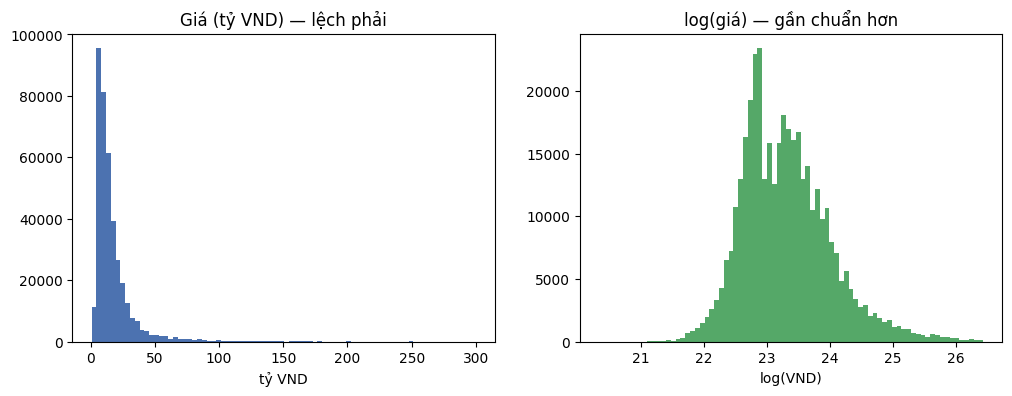

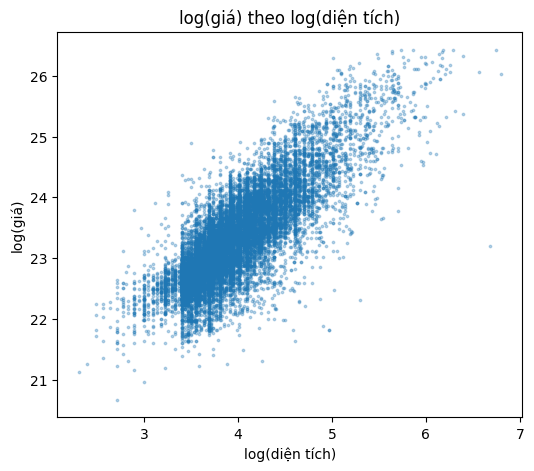

Số giá trị quận/huyện khác rỗng: 30 | phường/xã: 348


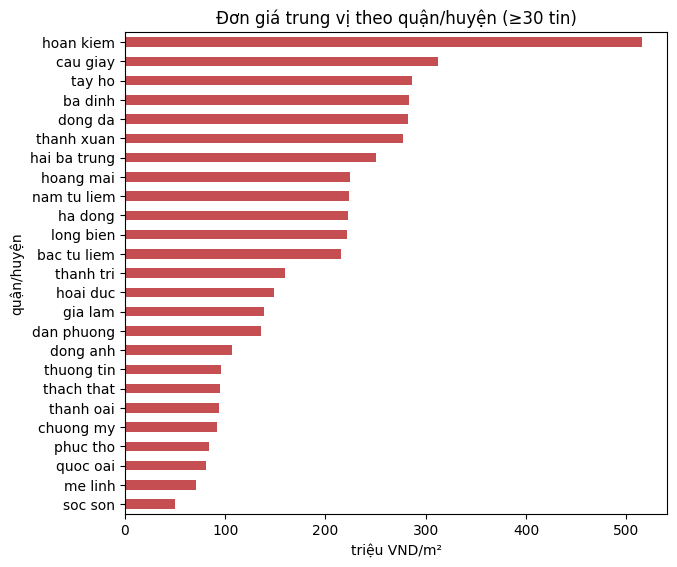

Đã lưu: D:\HocMay_GiaNha_KT1/survey\07_don_gia_theo_khu_vuc.csv


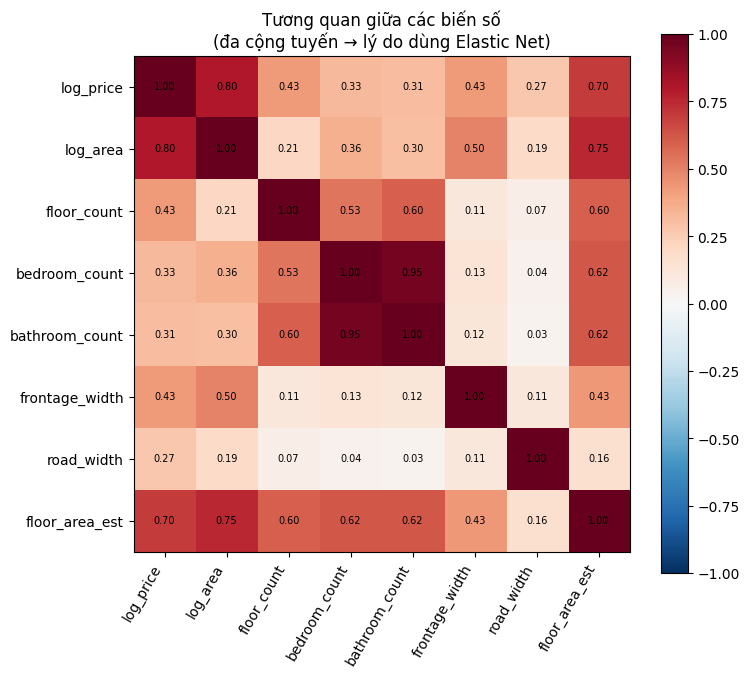

Đã lưu: D:\HocMay_GiaNha_KT1/survey\08_ty_le_thieu_ban_sach.csv


Đã lưu: D:\HocMay_GiaNha_KT1/survey\09_thong_ke_mo_ta_ban_sach.csv


,kieu,vai_tro,mo_ta,thieu_%
cot,,,,
date,datetime64[ns],thông tin,Ngày đăng,0.27
post_month,object,thông tin,Tháng đăng,0.27
title,object,thông tin,,0.00
district,object,thông tin,,0.00
ward,object,thông tin,,12.40
street,object,thông tin,,17.60
district_key,object,categorical,"Quận/huyện (cũ, đã chuẩn hoá khoá)",0.00
ward_key,object,thông tin,"Phường/xã (cũ, khoá)",12.40
ward_new,object,categorical,Phường/xã theo đơn vị hành chính mới,0.00


Đã lưu: D:\HocMay_GiaNha_KT1/survey\10_tu_dien_du_lieu.csv

Hoàn tất. Tất cả kết quả nằm trong: D:\HocMay_GiaNha_KT1


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(clean["price"] / 1e9, bins=80, color="#4C72B0")
axes[0].set_title("Giá (tỷ VND) — lệch phải"); axes[0].set_xlabel("tỷ VND")
axes[1].hist(clean["log_price"], bins=80, color="#55A868")
axes[1].set_title("log(giá) — gần chuẩn hơn"); axes[1].set_xlabel("log(VND)")
save_fig(fig, "02_phan_phoi_gia_va_log_gia")

fig, ax = plt.subplots(figsize=(6, 5))
s = clean.sample(min(20000, len(clean)), random_state=SEED)
ax.scatter(s["log_area"], s["log_price"], s=3, alpha=0.3)
ax.set_xlabel("log(diện tích)"); ax.set_ylabel("log(giá)"); ax.set_title("log(giá) theo log(diện tích)")
save_fig(fig, "03_log_gia_theo_log_dien_tich")

def unit_price_by(col, min_n=30, top=40):
    s = clean.loc[~clean[col].isin(["", "unknown"])]
    t = s.groupby(col)["unit_price"].agg(["median", "size"])
    t = t[t["size"] >= min_n].sort_values("median")
    return t.tail(top)

print("Số giá trị quận/huyện khác rỗng:", clean["district_key"].replace("", np.nan).nunique(),
      "| phường/xã:", clean["ward_new"].replace(["", "unknown"], np.nan).nunique())
# Dữ liệu sau sáp nhập có thể không còn cấp quận → tự chuyển sang phường; hạ ngưỡng số tin nếu cần
by_d, level = pd.DataFrame(), None
for col, lab in [("district_key", "quận/huyện"), ("ward_new", "phường/xã")]:
    for min_n in (30, 10):
        t = unit_price_by(col, min_n)
        if len(t) >= 3:
            by_d, level, used_n = t, lab, min_n
            break
    if level:
        break

if level:
    fig, ax = plt.subplots(figsize=(7, max(4, 0.25 * len(by_d))))
    (by_d["median"] / 1e6).plot.barh(ax=ax, color="#C44E52")
    ax.set_xlabel("triệu VND/m²"); ax.set_ylabel(level)
    ax.set_title(f"Đơn giá trung vị theo {level} (≥{used_n} tin)")
    save_fig(fig, "04_don_gia_theo_khu_vuc")
    save_table(by_d.rename(columns={"median": "don_gia_trung_vi", "size": "so_tin"}), "07_don_gia_theo_khu_vuc")
else:
    print("⚠ Không đủ tin theo quận/phường để vẽ — kiểm tra cột district/ward ở bước 2 và bảng phễu lọc")

num_for_corr = ["log_price"] + NUM_FEATURES + ["floor_area_est"]
corr = clean[num_for_corr].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Tương quan giữa các biến số\n(đa cộng tuyến → lý do dùng Elastic Net)")
save_fig(fig, "05_ma_tran_tuong_quan")

miss_clean = missing_table(clean)
save_table(miss_clean, "08_ty_le_thieu_ban_sach")
save_table(clean.describe().T.round(3), "09_thong_ke_mo_ta_ban_sach")

DICT = {
    "log_price": "Biến mục tiêu: log(giá VND)", "price": "Giá rao bán (VND) sau parse & sửa đơn vị",
    "price_raw": "Giá gốc trong dữ liệu (chuỗi)", "area": "Diện tích (m²)", "unit_price": "Đơn giá VND/m² (chỉ khảo sát)",
    "log_unit_price": "log(đơn giá) (chỉ khảo sát)", "log_area": "log(diện tích)",
    "floor_count": "Số tầng", "bedroom_count": "Số phòng ngủ", "bathroom_count": "Số phòng vệ sinh",
    "frontage_width": "Mặt tiền (m)", "house_depth": "Chiều sâu (m)", "road_width": "Độ rộng đường/ngõ trước nhà (m)",
    "depth_frontage_ratio": "Chiều sâu / mặt tiền", "floor_area_est": "Diện tích sàn ước tính (m²)",
    "road_type": "Loại đường: ngõ nhỏ <3m / ngõ ô tô 3–6m / đường lớn ≥6m / unknown",
    "dist_center_km": "Khoảng cách tới Hồ Gươm (km)", "log_dist_center": "log(1 + khoảng cách)",
    "house_direction": "Hướng nhà (8 hướng + Không rõ)", "district_key": "Quận/huyện (cũ, đã chuẩn hoá khoá)",
    "ward_key": "Phường/xã (cũ, khoá)", "ward_new": "Phường/xã theo đơn vị hành chính mới",
    "has_so_do": "Cờ: có sổ đỏ/sổ hồng", "car_access": "Cờ: ô tô vào/đỗ cửa", "is_mat_pho": "Cờ: mặt phố/mặt đường",
    "kinh_doanh": "Cờ: kinh doanh được", "lo_goc": "Cờ: lô góc/2 mặt thoáng", "no_hau": "Cờ: nở hậu",
    "thang_may": "Cờ: có thang máy", "split": "train/test", "date": "Ngày đăng", "post_month": "Tháng đăng",
}
role = {**{c: "target" for c in [TARGET]}, **{c: "numeric" for c in NUM_FEATURES},
        **{c: "binary" for c in BIN_FEATURES}, **{c: "categorical" for c in CAT_FEATURES}}
dd = pd.DataFrame({"cot": clean.columns,
                   "kieu": [str(t) for t in clean.dtypes],
                   "vai_tro": [role.get(c, "thông tin") for c in clean.columns],
                   "mo_ta": [DICT.get(c, "") for c in clean.columns],
                   "thieu_%": [miss_clean["thieu_%"].get(c, 0) for c in clean.columns]}).set_index("cot")
display(dd)
save_table(dd, "10_tu_dien_du_lieu")
print("\nHoàn tất. Tất cả kết quả nằm trong:", PROJECT_DIR)